In [11]:
import torch
import matplotlib.pyplot as plt

class BSplineBasis1D:
    def __init__(self, h, p, C, device=None):
        self.device = device if device else 'cpu'
        self.h = h
        self.p = p
        self.C = C

        # Construct uniform open knot vector
        kv = torch.zeros(p+1)
        interior = torch.linspace(0, 1, int((h - p - 1)/(p - C)) + 2)[1:-1]
        kv = torch.cat([kv, interior.repeat(p-C)])
        kv = torch.cat([kv, torch.ones(p+1)])
        self.knot_vector = kv.to(self.device)

    def forward(self, x):
        x = x.to(self.device)
        n_points = x.shape[0]
        h, p = self.h, self.p
        kv = self.knot_vector

        # Degree 0 basis
        N = ((x[:, None] >= kv[:-1][None, :]) & (x[:, None] < kv[1:][None, :])).float()

        # Recursion
        for k in range(1, p+1):
            left = torch.zeros_like(N)
            right = torch.zeros_like(N)
            for i in range(h):
                denom1 = kv[i+k] - kv[i]
                denom2 = kv[i+k+1] - kv[i+1]
                term1 = ((x - kv[i]) / denom1 * N[:, i]) if denom1 > 0 else 0
                term2 = ((kv[i+k+1] - x) / denom2 * N[:, i+1]) if denom2 > 0 and i+1 < h else 0
                left[:, i] = term1
                right[:, i] = term2
            N = left + right

        # Ensure last basis function = 1 at right endpoint
        N[x == kv[-1], -1] = 1.0

        return N

    def grad(self, x):
        x = x.to(self.device)
        n_points = x.shape[0]
        h, p = self.h, self.p
        kv = self.knot_vector

        if p == 0:
            return torch.zeros((n_points, h), device=self.device)

        # Degree 0 basis for lower degree recursion
        N = ((x[:, None] >= kv[:-1][None, :]) & (x[:, None] < kv[1:][None, :])).float()

        for k in range(1, p):
            left = torch.zeros_like(N)
            right = torch.zeros_like(N)
            for i in range(h):
                denom1 = kv[i+k] - kv[i]
                denom2 = kv[i+k+1] - kv[i+1]
                term1 = ((x - kv[i]) / denom1 * N[:, i]) if denom1 > 0 else 0
                term2 = ((kv[i+k+1] - x) / denom2 * N[:, i+1]) if denom2 > 0 and i+1 < h else 0
                left[:, i] = term1
                right[:, i] = term2
            N = left + right

        # Compute derivative
        dN = torch.zeros_like(N)
        for i in range(h):
            denom1 = kv[i+p] - kv[i]
            denom2 = kv[i+p+1] - kv[i+1]
            term1 = (p / denom1 * N[:, i]) if denom1 > 0 else 0
            term2 = (p / denom2 * N[:, i+1]) if denom2 > 0 and i+1 < h else 0
            dN[:, i] = term1 - term2

        # Ensure derivative is zero at the right endpoint
        dN[x == kv[-1], :] = 0.0

        return dN

    def plot_1d_basis(self):
        knots = self.knot_vector
        resolution = 1000
        x_values = torch.linspace(knots[self.p], knots[-self.p-1], resolution, device=self.device)
        basis_matrix = self.forward(x_values).cpu().numpy()
        plt.figure(figsize=(8, 6))
        for i in range(self.h):
            plt.plot(x_values.cpu(), basis_matrix[:, i], label=f'Basis {i}')
        plt.title(f'1D Basis Functions')
        plt.xlabel('x')
        plt.ylabel('Basis Values')
        plt.legend()
        plt.grid(True)
        plt.show()

    def plot_1d_basis_gradients(self):
        knots = self.knot_vector
        resolution = 1000
        x_values = torch.linspace(knots[self.p], knots[-self.p-1], resolution, device=self.device)
        basis_gradients_matrix = self.grad(x_values).cpu().numpy()
        plt.figure(figsize=(8, 6))
        for i in range(self.h):
            plt.plot(x_values.cpu(), basis_gradients_matrix[:, i], label=f'Gradient {i}')
        plt.title(f'Gradients of 1D Basis Functions')
        plt.xlabel('x')
        plt.ylabel('Gradient Values')
        plt.legend()
        plt.grid(True)
        plt.show()


In [12]:
basis = BSplineBasis1D(h=10, p=3, C=2)

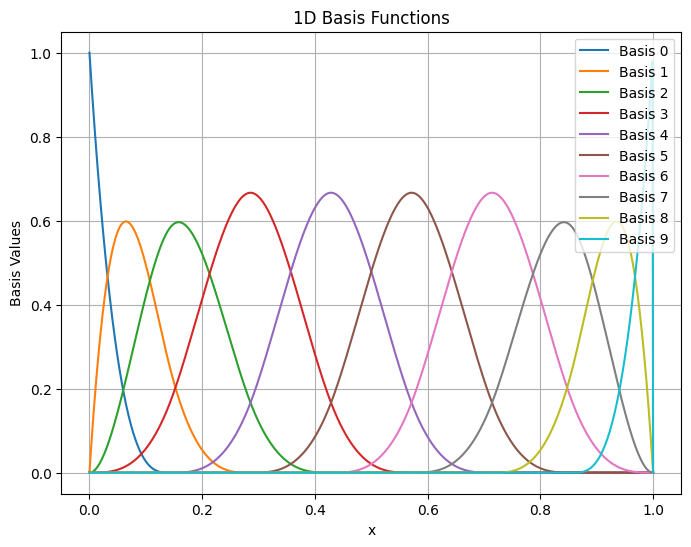

In [13]:
basis.plot_1d_basis()